In [1]:
from PIL import Image

blank = Image.open("train_data/empty_piano_score.png")
notes = Image.open("train_data/all_piano_notes_duration.png")

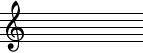

In [2]:
blank

In [3]:
notes

In [4]:
# IN THE FOLDER test_data ARE ALL THE IMAGES

random_image = Image.open("test_data/2.png")

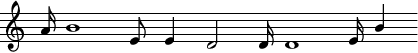

In [5]:
random_image

In [9]:
import matplotlib.pyplot as plt
import cv2 as cv
import numpy as np

def get_count(img):
    img = np.array(img)
    imgray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    img = cv.medianBlur(imgray, 3)
    ret, thresh = cv.threshold(img, 127, 255, 0)
    contours, hierarchy = cv.findContours(thresh, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

    good_contours = []
    for cnt in contours:
        area = cv.contourArea(cnt)
        if area > 60 and area < 400:
            good_contours.append(cnt)
    
    return len(good_contours)-1

get_count(random_image)

9

In [10]:
import glob
import os
from tqdm import tqdm
import pandas as pd

test_paths = sorted(glob.glob("test_data/*.png"))

results = []

for path in tqdm(test_paths):
  dp_id = int(os.path.basename(path).split('.')[0])
  img = Image.open(path)

  ans_subtask1  = get_count(img)
  ans_subtask2  = 0
  ans_subtask3  = ""

  results.extend([[1, dp_id, ans_subtask1], [2, dp_id, ans_subtask2], [3, dp_id, ans_subtask3]])

submission = pd.DataFrame(results, columns=["subtaskID", "datapointID", "answer"])
submission

100%|█████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:04<00:00, 409.74it/s]


,subtaskID,datapointID,answer
0,1,0,4
1,2,0,0
2,3,0,
3,1,1,2
4,2,1,0
...,...,...,...
5995,2,998,0
5996,3,998,
5997,1,999,56
5998,2,999,0


In [11]:
submission.to_csv("submission.csv", index=False)